**Praktikum Week 9 Mata Kuliah Kecerdasan Buatan** <br>
Materi: Neural Network <br>
By: TAP

Eben Manurung
42324024 <br>
D3 Teknologi Informasi <br>
2024

A. Penambahan library dan instalasi
Pada notebook asli, library yang digunakan adalah NumPy, Matplotlib, dan TensorFlow.

Pada implementasi baru, kita menambahkan library datasets dari Hugging Face.

In [24]:
%pip install numpy matplotlib tensorflow

Note: you may need to restart the kernel to use updated packages.


In [25]:
!pip install numpy matplotlib

In [26]:
%pip install --upgrade pip
%pip install numpy matplotlib tensorflow datasets

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


Alasan penambahan:

Dataset Fashion MNIST pada program awal sudah tersedia melalui TensorFlow Keras. Sementara itu, dataset Fruits-360 yang kita gunakan dimuat melalui Hugging Face.

Oleh karena itu, diperlukan library datasets agar Python dapat mengambil dan membaca dataset tersebut.

Kita juga menggunakan lingkungan Python yang kompatibel dengan TensorFlow. Dalam proses pengerjaan, Python 3.14 yang digunakan pada awalnya belum menyediakan TensorFlow pada lingkungan tersebut. Karena itu, kita menyiapkan lingkungan Python 3.12 dan menghubungkannya dengan VS Code melalui Jupyter Kernel.

Penambahan ini diperlukan agar seluruh library dapat ditemukan dan digunakan oleh notebook.

B. Perubahan import library
Notebook asli menggunakan:

Penggunaan TensorFlow tetap dipertahankan karena algoritma utama yang digunakan masih sama dengan praktikum

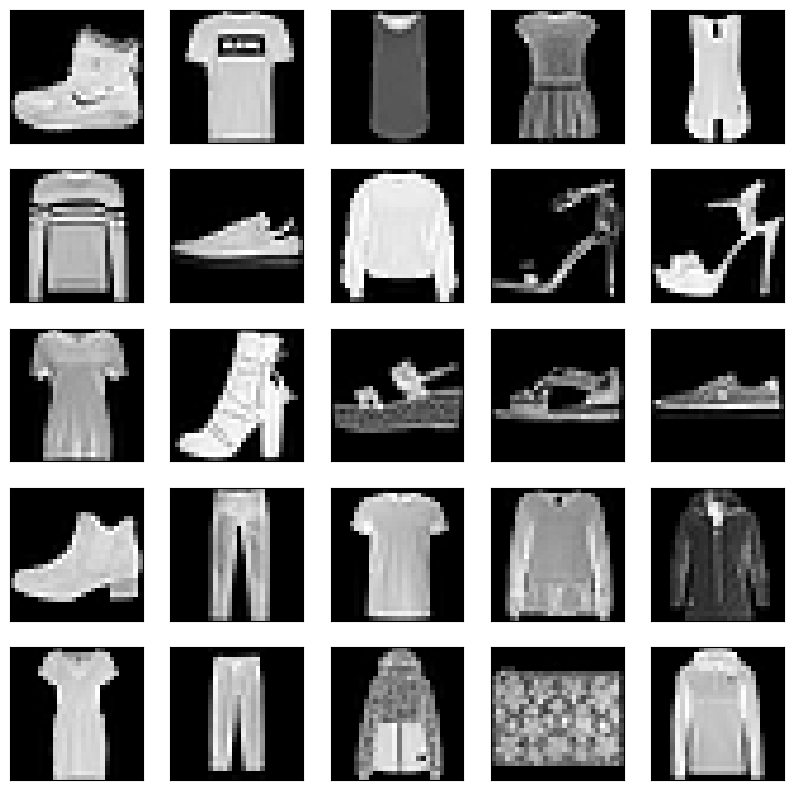

In [27]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
import matplotlib.pyplot as plt

# Load dataset Fashion MNIST
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

# Normalize nilai piksel gambar ke rentang [0,1]
train_images = train_images / 255.0
test_images = test_images / 255.0

# Melihat contoh gambar
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i], cmap='gray')
plt.show()


Fungsi kode: Memuat dan mempersiapkan dataset Fashion MNIST sebelum digunakan untuk pelatihan Neural Network.

Penjelasan singkat:
1. Import library: Memanggil TensorFlow, dataset Fashion MNIST, dan Matplotlib.
2. Load dataset: Mengambil gambar dan label, kemudian membaginya menjadi data training dan testing.
3. Normalisasi: Mengubah nilai piksel dari 0–255 menjadi 0–1 agar lebih mudah diproses model.
4. Visualisasi: Menampilkan 25 contoh gambar pakaian dalam format hitam putih dengan susunan 5 × 5.
Hasil: Ditampilkan 25 gambar pakaian dari Fashion MNIST sebagai contoh data yang akan dipelajari oleh Neural Network.

dan tujuan nya: Memastikan dataset berhasil dimuat dan dipersiapkan sebelum masuk ke tahap pembuatan serta pelatihan model.

In [28]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Flatten, Dense

# Membuat model Neural Network
model = Sequential([
    Flatten(input_shape=(28, 28)),  # Mengubah gambar 28x28 menjadi vektor 1D dengan panjang 784
    Dense(128, activation='relu'),  # Hidden layer dengan 128 neuron
    Dense(10, activation='softmax')  # Output layer dengan 10 neuron untuk klasifikasi 10 kategori
])

# Melihat ringkasan arsitektur model
model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Fungsi kode: Membuat arsitektur model Neural Network untuk mengklasifikasikan 10 kategori gambar pakaian pada dataset Fashion MNIST.

Penjelasan singkat:
1. Import library: Mengambil Sequential, Flatten, dan Dense dari TensorFlow Keras.
2. Sequential: Menyusun lapisan Neural Network secara berurutan.
3. Flatten: Mengubah gambar berukuran 28 × 28 piksel menjadi vektor satu dimensi dengan 784 nilai.
4. Dense(128, activation='relu'): Membuat hidden layer dengan 128 neuron untuk mempelajari pola dan karakteristik gambar.
5. Dense(10, activation='softmax'): Membuat output layer dengan 10 neuron untuk menghasilkan prediksi dari 10 kategori pakaian.
6. model.summary(): Menampilkan ringkasan arsitektur model, termasuk jumlah lapisan, bentuk output, dan parameter model.
Hasil: Terbentuk model Neural Network dengan satu input layer (Flatten), satu hidden layer (128 neuron), dan satu output layer (10 neuron).

Tujuan: Membangun model yang mampu mempelajari karakteristik gambar pakaian dan mengklasifikasikannya ke dalam 10 kategori Fashion MNIST.

In [29]:
# Kompilasi model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Melatih model dengan data training
history = model.fit(train_images, train_labels, epochs=10, validation_data=(test_images, test_labels))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 33s 15ms/step - accuracy: 0.8253 - loss: 0.4970 - val_accuracy: 0.8502 - val_loss: 0.4254
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 24s 13ms/step - accuracy: 0.8635 - loss: 0.3754 - val_accuracy: 0.8626 - val_loss: 0.3822
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.8770 - loss: 0.3357 - val_accuracy: 0.8688 - val_loss: 0.3682
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8859 - loss: 0.3099 - val_accuracy: 0.8715 - val_loss: 0.3548
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.8921 - loss: 0.2921 - val_accuracy: 0.8762 - val_loss: 0.3466
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.8982 - loss: 0.2756 - val_accuracy: 0.8769 - val_loss: 0.3483
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.9023 - loss: 0.2626 - val_accuracy: 0.8755 - val_loss: 0.3546
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9065 - loss: 

Fungsi kode: Mengatur konfigurasi pembelajaran model (compile) dan melatih Neural Network menggunakan data Fashion MNIST.

Penjelasan singkat:

1. model.compile(): Menyiapkan model sebelum proses training.
- optimizer='adam': Mengatur cara model memperbarui bobot selama pembelajaran.
- loss='sparse_categorical_crossentropy': Menghitung kesalahan prediksi untuk klasifikasi dengan label berbentuk angka.
- metrics=['accuracy']: Mengukur tingkat ketepatan prediksi model.
2. model.fit(): Menjalankan proses pelatihan menggunakan train_images dan train_labels.

3. epochs=10: Model mempelajari seluruh data training sebanyak 10 putaran.

4. validation_data=(test_images, test_labels): Menggunakan data testing untuk memantau performa model pada setiap epoch.

5. history: Menyimpan riwayat hasil training, seperti nilai accuracy dan loss.

Hasil: Model dilatih selama 10 epochs dan menampilkan perkembangan akurasi serta kesalahan pembelajaran pada setiap putaran.

Tujuan: Membuat model mempelajari pola gambar pakaian sehingga dapat mengenali dan mengklasifikasikan 10 kategori Fashion MNIST.

In [30]:
# Evaluasi model dengan data pengujian
test_loss, test_acc = model.evaluate(test_images, test_labels)

print(f'\nTest accuracy: {test_acc}')


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8801 - loss: 0.3514

Test accuracy: 0.8801000118255615


Fungsi kode: Mengevaluasi performa model Neural Network menggunakan data testing yang sebelumnya tidak digunakan sebagai data training.

Penjelasan singkat:
1. model.evaluate(): Menguji model menggunakan test_images dan test_labels.
2. test_loss: Menyimpan nilai kesalahan prediksi model. Semakin kecil nilainya, semakin baik.
3. test_acc: Menyimpan nilai akurasi model, yaitu persentase prediksi yang benar.
4. print(): Menampilkan hasil akurasi pengujian ke layar.
Hasil: Menampilkan nilai Test Loss dan Test Accuracy yang menunjukkan kemampuan model dalam mengklasifikasikan gambar pakaian.

Tujuan: Mengetahui seberapa baik model mengenali kategori pakaian berdasarkan data pengujian.

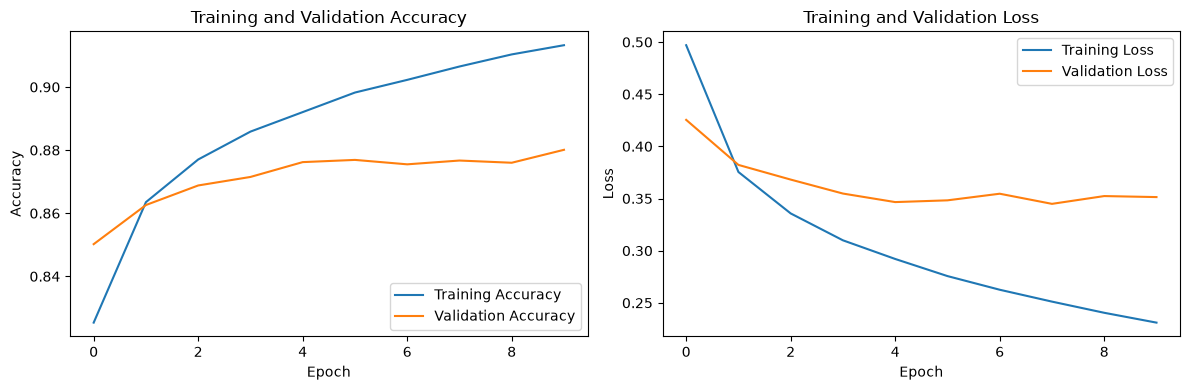

In [31]:
# Mendefinisikan fungsi untuk memvisualisasikan akurasi dan loss
def plot_history(history):
    # Plot akurasi
    plt.figure(figsize=(12, 4))

    # Plot Akurasi
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')

    # Tampilkan plot
    plt.tight_layout()
    plt.show()

# Memanggil fungsi visualisasi
plot_history(history)

Fungsi kode: Menampilkan grafik perkembangan akurasi (accuracy) dan tingkat kesalahan (loss) model selama proses training dan validasi.

Penjelasan singkat:
1. def plot_history(history): Membuat fungsi untuk menampilkan riwayat hasil pelatihan model.
2. Grafik Accuracy: Membandingkan akurasi data training (accuracy) dan data validasi (val_accuracy) pada setiap epoch.
3. Grafik Loss: Membandingkan tingkat kesalahan data training (loss) dan data validasi (val_loss).
4. plt.subplot(1, 2, 1): Menampilkan grafik akurasi di sebelah kiri.
5. plt.subplot(1, 2, 2): Menampilkan grafik loss di sebelah kanan.
6. plt.legend(): Memberikan keterangan pada setiap garis grafik.
7. plot_history(history): Memanggil fungsi agar kedua grafik ditampilkan.
Hasil: Dua grafik, yaitu Training and Validation Accuracy dan Training and Validation Loss, yang menunjukkan perkembangan performa model selama 10 epochs.

Tujuan: Mengetahui apakah model mengalami peningkatan pembelajaran dan melihat perbedaan performanya pada data training dan validasi.

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


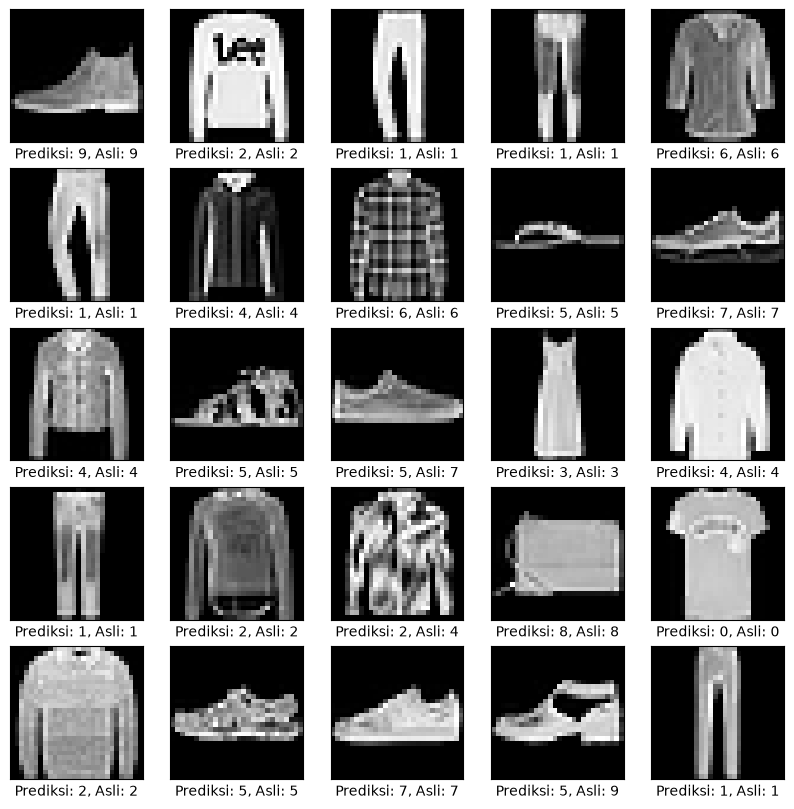

In [32]:
# Melakukan prediksi pada gambar pengujian
import numpy as np
predictions = model.predict(test_images)

# Contoh prediksi untuk 25 gambar pertama
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(test_images[i], cmap='gray')
    predicted_label = np.argmax(predictions[i])
    actual_label = test_labels[i]
    plt.xlabel(f"Prediksi: {predicted_label}, Asli: {actual_label}")
plt.show()


Fungsi kode: Melakukan prediksi terhadap gambar pada data testing menggunakan model Neural Network yang sudah dilatih.

Penjelasan singkat:
1. import numpy as np: Mengimpor NumPy untuk membantu pengolahan hasil prediksi.
2. model.predict(test_images): Meminta model memprediksi kategori seluruh gambar pada data testing.
3. plt.figure(figsize=(10, 10)): Menyiapkan area visualisasi gambar.
4. for i in range(25): Mengambil 25 gambar pertama dari data testing untuk ditampilkan.
5. plt.imshow(test_images[i], cmap='gray'): Menampilkan gambar dalam format hitam putih.
6. np.argmax(predictions[i]): Mengambil nomor kategori dengan nilai prediksi tertinggi dari model.
7. test_labels[i]: Mengambil nomor kategori sebenarnya dari gambar tersebut.
8. plt.xlabel(): Menampilkan label prediksi dan label sebenarnya di bawah gambar.
Hasil: Menampilkan 25 gambar pakaian beserta nomor kategori hasil prediksi dan kategori sebenarnya.

Tujuan: Melihat kemampuan model dalam mengenali gambar dan membandingkan hasil prediksi dengan label sebenarnya untuk mengetahui apakah klasifikasi sudah tepat.

**Tugas** <br>
Implementasikan kode program di atas dengan dataset yang berbeda serta jelaskan apa yang Anda buat. Tugas dikumpulkan di hari Selasa, 3 Oktober 2026 jam 23.59 WIB di ecourse (baru).

Berdasarkan praktikum Neural Network, dapat disimpulkan bahwa model Neural Network menggunakan TensorFlow berhasil diterapkan untuk melakukan klasifikasi gambar pada dataset Fashion MNIST.

Proses praktikum dimulai dari memuat dataset, melakukan normalisasi nilai piksel, dan menampilkan contoh gambar. Selanjutnya, model dibangun menggunakan arsitektur Sequential yang terdiri dari lapisan Flatten, Dense dengan 128 neuron, dan Dense dengan 10 neuron output. Model kemudian dilatih selama 10 epochs, dievaluasi, dan digunakan untuk memprediksi gambar pada data testing.

Berdasarkan hasil pada modul, model memperoleh akurasi pengujian sebesar 88,03%. Hasil ini menunjukkan bahwa model mampu mengenali dan mengklasifikasikan sebagian besar gambar pakaian dengan cukup baik. Melalui praktikum ini, dapat dipahami bagaimana Neural Network bekerja mulai dari persiapan data, proses pelatihan, evaluasi, hingga menghasilkan prediksi.